<a href="https://colab.research.google.com/github/XclaimR/hf-agents-course-final/blob/main/hf_agents_final_langgraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HF Agents Course: Unit 4 Final Assignment (LangGraph + Gemini, Colab)

**Before running:** click the key icon in Colab's left sidebar (Secrets) and add `GEMINI_API_KEY`
(free from aistudio.google.com, no card), with "Notebook access" turned on.

Then set your HF username in the config cell and run cells top to bottom.
Optional: Runtime > Change runtime type > T4 GPU makes audio transcription faster.

In [1]:
!pip install -q langgraph langchain-core langchain-google-genai langchain-community ddgs wikipedia youtube-transcript-api openpyxl openai-whisper beautifulsoup4

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 15.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 kB 741.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.6/81.6 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 46.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.2/485.2 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 72.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [12]:
import os, json, time, re, base64, mimetypes, requests
from google.colab import userdata

os.environ["GOOGLE_API_KEY"] = userdata.get("GEMINI_API_KEY")
HF_USERNAME = "XclaimR"          # <-- change this
CODE_URL = "https://github.com/your-username/hf-agents-final"  # <-- public link to your code
MODEL_ID = "gemini-3.1-flash-lite"             # check AI Studio for the current free Flash model name

API = "https://agents-course-unit4-scoring.hf.space"
FILES_DIR = "/content/gaia_files"
CACHE = "/content/answers.json"
os.makedirs(FILES_DIR, exist_ok=True)

## 1. Download the questions and their attached files

In [13]:
from huggingface_hub import hf_hub_download

questions = requests.get(f"{API}/questions", timeout=30).json()
print(len(questions), "questions")

try:
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = None

def fetch_file(q):
    path = os.path.join(FILES_DIR, q["file_name"])
    if os.path.exists(path):
        return path
    # 1. Try the course API
    r = requests.get(f"{API}/files/{q['task_id']}", timeout=60)
    if r.ok:
        with open(path, "wb") as f:
            f.write(r.content)
        return path
    # 2. Fall back to the original GAIA dataset (needs HF_TOKEN + accepted dataset terms)
    if HF_TOKEN:
        try:
            return hf_hub_download(
                repo_id="gaia-benchmark/GAIA", repo_type="dataset",
                filename=f"2023/validation/{q['file_name']}",
                token=HF_TOKEN, local_dir=FILES_DIR,
            )
        except Exception as e:
            print(f"  GAIA fallback failed for {q['file_name']}: {e}")
    print(f"  Missing file for task {q['task_id']} ({q['file_name']}), agent will answer without it")
    return None

for q in questions:
    q["local_path"] = fetch_file(q) if q.get("file_name") else None

for i, q in enumerate(questions):
    flag = "" if not q["file_name"] or q["local_path"] else "  <-- FILE MISSING"
    print(i, "|", q["file_name"] or "-", "|", q["question"][:100].replace("\n", " "), flag)

20 questions
  GAIA fallback failed for cca530fc-4052-43b2-b130-b30968d8aa44.png: 401 Client Error. (Request ID: Root=1-6ac4cdeb-294ff2f715d01f877f381036;4b16632a-a666-4f69-94cc-ada6547ab249)

Cannot access gated repo for url https://huggingface.co/datasets/gaia-benchmark/GAIA/resolve/main/2023/validation/cca530fc-4052-43b2-b130-b30968d8aa44.png.
Access to dataset gaia-benchmark/GAIA is restricted. You must have access to it and be authenticated to access it. Please log in.
  Missing file for task cca530fc-4052-43b2-b130-b30968d8aa44 (cca530fc-4052-43b2-b130-b30968d8aa44.png), agent will answer without it
  GAIA fallback failed for 99c9cc74-fdc8-46c6-8f8d-3ce2d3bfeea3.mp3: 401 Client Error. (Request ID: Root=1-6ac4cdec-0f61e28d5421f1f3066764c5;11b99c01-0c8a-42cc-86a2-d9601b019e3f)

Cannot access gated repo for url https://huggingface.co/datasets/gaia-benchmark/GAIA/resolve/main/2023/validation/99c9cc74-fdc8-46c6-8f8d-3ce2d3bfeea3.mp3.
Access to dataset gaia-benchmark/GAIA is restricted

## 2. Tools

In [19]:
import io, contextlib
import pandas as pd
from bs4 import BeautifulSoup
from langchain_core.tools import tool

@tool
def web_search(query: str) -> str:
    """Search the web with DuckDuckGo. Returns titles, URLs and snippets of the top results."""
    from ddgs import DDGS
    try:
        results = DDGS().text(query, max_results=6)
    except Exception as e:
        return f"Search failed: {e}"
    return "\n\n".join(f"{r['title']}\n{r['href']}\n{r['body']}" for r in results) or "No results."

@tool
def wikipedia_search(query: str) -> str:
    """Search English Wikipedia and return the best matching page as text, INCLUDING tables
    (discographies, filmographies, stats). Truncated to 40000 characters."""
    import wikipedia
    try:
        title = wikipedia.search(query)[0]
        page = wikipedia.page(title, auto_suggest=False)
        soup = BeautifulSoup(page.html(), "html.parser")
        for t in soup(["script", "style", "sup"]):
            t.decompose()
        text = re.sub(r"\n{3,}", "\n\n", soup.get_text("\n"))
        return f"{page.title}\n{page.url}\n\n{text[:40000]}"
    except Exception as e:
        return f"Wikipedia lookup failed: {e}"

@tool
def visit_webpage(url: str) -> str:
    """Fetch a web page and return its visible text, including tables (truncated to 40000 characters)."""
    try:
        html = requests.get(url, timeout=20, headers={"User-Agent": "Mozilla/5.0"}).text
    except Exception as e:
        return f"Fetch failed: {e}"
    soup = BeautifulSoup(html, "html.parser")
    for t in soup(["script", "style", "nav", "footer"]):
        t.decompose()
    return re.sub(r"\n{3,}", "\n\n", soup.get_text("\n"))[:40000]

@tool
def read_file(path: str) -> str:
    """Read a local attached file and return its contents as text.
    Supports .csv, .xlsx/.xls (all sheets), .py, .txt, .json, .md."""
    ext = os.path.splitext(path)[1].lower()
    if ext in (".xlsx", ".xls"):
        sheets = pd.read_excel(path, sheet_name=None)
        return "\n\n".join(f"Sheet {n}:\n{df.to_string()}" for n, df in sheets.items())
    if ext == ".csv":
        return pd.read_csv(path).to_string()
    with open(path, "r", errors="ignore") as f:
        return f.read()

_whisper = None
@tool
def transcribe_audio(path: str) -> str:
    """Transcribe a local audio file (mp3, wav, m4a) to text."""
    global _whisper
    import whisper
    if _whisper is None:
        _whisper = whisper.load_model("base")
    return _whisper.transcribe(path)["text"]

@tool
def youtube_transcript(url: str) -> str:
    """Get the spoken-word transcript of a YouTube video. Does not describe visuals."""
    from youtube_transcript_api import YouTubeTranscriptApi
    m = re.search(r"(?:v=|youtu\.be/|shorts/)([\w-]{11})", url)
    if not m:
        return "Could not find a video id in the URL."
    try:
        return " ".join(s.text for s in YouTubeTranscriptApi().fetch(m.group(1)))
    except Exception as e:
        return f"Transcript unavailable: {e}"

@tool
def run_python(code: str) -> str:
    """Execute Python code and return whatever it prints. Use print() for results.
    Good for arithmetic, counting, dates, string puzzles, or running an attached .py file
    (e.g. code = open('/path/file.py').read())."""
    buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(buf):
            exec(code, {"__name__": "__main__"})
    except Exception as e:
        return buf.getvalue() + f"\nError: {type(e).__name__}: {e}"
    return buf.getvalue()[:10000] or "(no output, did you print?)"

tools = [web_search, visit_webpage, wikipedia_search, read_file,
         transcribe_audio, youtube_transcript, run_python]

## 3. Build the LangGraph agent

A classic ReAct loop, built by hand like in Unit 2.3:
`START -> assistant -> (tools -> assistant)* -> END`

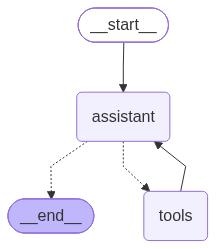

In [20]:
from typing import Annotated, TypedDict
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

SYSTEM_PROMPT = """You are a careful research assistant answering questions from the GAIA benchmark.
Use the tools to find and verify facts. Do not guess when a tool can confirm.
When you are done, reply with ONLY the final answer, nothing else. Scoring is EXACT MATCH:
- No explanation, no 'FINAL ANSWER:' prefix, no full sentences.
- A number: digits only, no commas, no units ($, %, km) unless the question asks for them.
- A string: no articles, no abbreviations unless asked.
- A list: comma-separated, in the order/format the question asks for.
- Follow any formatting the question specifies exactly."""

llm = ChatGoogleGenerativeAI(model=MODEL_ID, temperature=0, max_retries=3)
llm_with_tools = llm.bind_tools(tools)

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

MAX_TOOL_ROUNDS = 12

def assistant(state: AgentState):
    msgs = [SystemMessage(content=SYSTEM_PROMPT)] + state["messages"]
    rounds = sum(1 for m in state["messages"] if m.type == "ai")
    if rounds >= MAX_TOOL_ROUNDS:
        msgs.append(HumanMessage(content="You are out of tool calls. Reply now with ONLY your best final answer."))
        return {"messages": [llm.invoke(msgs)]}
    return {"messages": [llm_with_tools.invoke(msgs)]}

builder = StateGraph(AgentState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")
builder.add_conditional_edges("assistant", tools_condition)  # tool call -> "tools", else END
builder.add_edge("tools", "assistant")
graph = builder.compile()

from IPython.display import Image, display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    print(graph.get_graph().draw_ascii())

## 4. Run one question (handles images natively) and clean the answer

In [21]:
IMAGE_EXT = (".png", ".jpg", ".jpeg", ".webp", ".gif")

def build_message(q):
    text = "Question:\n" + q["question"]
    p = q.get("local_path")
    if p and not p.lower().endswith(IMAGE_EXT):
        text += f"\n\nAttached file saved locally at: {p}"
        text += "\nUse read_file for spreadsheets/code/text, transcribe_audio for audio, run_python to execute code."
    content = [{"type": "text", "text": text}]
    if p and p.lower().endswith(IMAGE_EXT):
        mime = mimetypes.guess_type(p)[0] or "image/png"
        b64 = base64.b64encode(open(p, "rb").read()).decode()
        content.append({"type": "image_url", "image_url": f"data:{mime};base64,{b64}"})
    return HumanMessage(content=content)

def message_text(msg):
    c = msg.content
    if isinstance(c, list):  # Gemini sometimes returns a list of parts
        c = " ".join(part.get("text", "") if isinstance(part, dict) else str(part) for part in c)
    return str(c)

def clean(ans):
    s = ans.strip()
    s = re.sub(r"^(final answer|answer)\s*[:\-]\s*", "", s, flags=re.I)
    s = s.strip().strip('"').strip("'").strip("*").strip()
    if s.endswith(".") and not re.search(r"\d\.$", s[-3:]):
        s = s[:-1]
    return s.strip()

def solve(q, verbose=False):
    result = graph.invoke({"messages": [build_message(q)]}, config={"recursion_limit": 30})
    if verbose:
        for m in result["messages"]:
            m.pretty_print()
    return clean(message_text(result["messages"][-1]))

## 5. Test on a single question first (verbose shows every tool call)

In [22]:
q = questions[0]
print(q["question"], "\n")
print("\nANSWER:", solve(q, verbose=True))

How many studio albums were published by Mercedes Sosa between 2000 and 2009 (included)? You can use the latest 2022 version of english wikipedia. 

================================ Human Message =================================

[{'type': 'text', 'text': 'Question:\nHow many studio albums were published by Mercedes Sosa between 2000 and 2009 (included)? You can use the latest 2022 version of english wikipedia.'}]
================================== Ai Message ==================================

[]
Tool Calls:
  wikipedia_search (call_64941)
 Call ID: call_64941
  Args:
    query: Mercedes Sosa discography
================================= Tool Message =================================
Name: wikipedia_search

Mercedes Sosa
https://en.wikipedia.org/wiki/Mercedes_Sosa

Argentine singer (1935–2009)

Not to be confused with 
Mercedes Sola
.

In this name that follows 
Hispanic American naming customs
, the first or paternal 
surname
 is 
 Sosa
 and the second or maternal family name is 
 G

## 6. Run all 20 (cached, so you can re-run safely after a crash or rate limit)

In [23]:
answers = json.load(open(CACHE)) if os.path.exists(CACHE) else {}

for i, q in enumerate(questions):
    tid = q["task_id"]
    if tid in answers and answers[tid] not in ("", "ERROR"):
        continue
    for attempt in range(3):
        try:
            answers[tid] = solve(q)
            break
        except Exception as e:
            print(f"[{i}] attempt {attempt+1} failed: {type(e).__name__}: {str(e)[:200]}")
            answers[tid] = "ERROR"
            time.sleep(30)  # back off on rate limits
    json.dump(answers, open(CACHE, "w"), indent=2)
    print(f"[{i}] {answers[tid]}")
    time.sleep(6)  # stay under free-tier requests per minute

[1] 3
[2] right


[3] Qh1+
[4] attempt 1 failed: GoogleRateLimitError: Error calling model 'gemini-3.1-flash-lite' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing detail
[4] FunkMonk
[5] b,e
[6] extremely
[7] attempt 1 failed: GoogleRateLimitError: Error calling model 'gemini-3.1-flash-lite' (RESOURCE_EXHAUSTED): 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing detail
[7] Louvrier
[8] broccoli, celery, fresh basil, lettuce, sweet potatoes


100%|████████████████████████████████████████| 139M/139M [00:01<00:00, 105MiB/s]
/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


[9] attempt 1 failed: RuntimeError: Failed to load audio: ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 


/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


[9] attempt 2 failed: RuntimeError: Failed to load audio: ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 


/usr/local/lib/python3.13/dist-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


[9] attempt 3 failed: RuntimeError: Failed to load audio: ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 


KeyboardInterrupt: 

## 7. Review before submitting
Look for answers that are sentences, have units, or say ERROR. To debug one: `solve(questions[i], verbose=True)`.
To redo one: `answers.pop(questions[i]["task_id"])` and re-run step 6.

In [24]:
pd.set_option("display.max_colwidth", 120)
pd.DataFrame([{"i": i, "question": q["question"][:100], "answer": answers.get(q["task_id"])}
              for i, q in enumerate(questions)])

,i,question,answer
0,0,How many studio albums were published by Mercedes Sosa between 2000 and 2009 (included)? You can use,6
1,1,"In the video https://www.youtube.com/watch?v=L1vXCYZAYYM, what is the highest number of bird species",3
2,2,".rewsna eht sa ""tfel"" drow eht fo etisoppo eht etirw ,ecnetnes siht dnatsrednu uoy fI",right
3,3,Review the chess position provided in the image. It is black's turn. Provide the correct next move f,Qh1+
4,4,Who nominated the only Featured Article on English Wikipedia about a dinosaur that was promoted in N,FunkMonk
5,5,"Given this table defining * on the set S = {a, b, c, d, e}\n\n|*|a|b|c|d|e|\n|---|---|---|---|---|---|\n","b,e"
6,6,Examine the video at https://www.youtube.com/watch?v=1htKBjuUWec.\n\nWhat does Teal'c say in response,extremely
7,7,What is the surname of the equine veterinarian mentioned in 1.E Exercises from the chemistry materia,Louvrier
8,8,"I'm making a grocery list for my mom, but she's a professor of botany and she's a real stickler when","broccoli, celery, fresh basil, lettuce, sweet potatoes"
9,9,"Hi, I'm making a pie but I could use some help with my shopping list. I have everything I need for t",ERROR


## 8. Submit

In [ ]:
payload = {
    "username": HF_USERNAME,
    "agent_code": CODE_URL,
    "answers": [{"task_id": q["task_id"], "submitted_answer": answers.get(q["task_id"], "")}
                for q in questions],
}
r = requests.post(f"{API}/submit", json=payload, timeout=120)
print(r.status_code)
print(json.dumps(r.json(), indent=2))